# Chapter 78: Rent-Seeking, Regulation, Capture, and Jurisdictional Arbitrage

This notebook reruns four worked examples from the chapter: a Peltzman markup as consumers organize, a tariff sold to a lobby, the resources burned in a rent-seeking contest, and a usury cap with fees and collateral. Every number is one of the chapter's hypothetical teaching numbers, not market data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def peltzman_markup(a, k, benchmark):
    """Peltzman markup with support a m - m^2/2 and opposition k m^2: a - m = 2 k m, m* = a/(1 + 2k).

    Principle: peltzman-regulatory-equilibrium (ch078). Book: a = 10, k = 1.25 gives m* = 20/7 = 2.86
    and price 17.86 on a 15 benchmark; k = 2.5 gives 5/3 = 1.67 and 16.67.
    """
    m = a / (1 + 2 * k)
    return {"m": m, "price": benchmark + m, "support": a * m - 0.5 * m * m - k * m * m}


def binary_menu_auction(w_free, w_tariff, gain, offer, a, counter=0.0):
    """Binary protection-for-sale choice: tariff advantage offer - a(w_free - w_tariff) against counter.

    Principle: protection-for-sale-model (ch078). Book: 2.5(900 - 870) = 75, 90 - 75 = 15, lobby keeps
    120 - 90 = 30; a = 4 gives a loss of 120; with a counter offer of 20 the tariff needs more than 95.
    Returns loss, advantage, keep, threshold and choice ('tariff', 'free trade' or 'tie').
    """
    loss = a * (w_free - w_tariff)
    adv = offer - loss
    if abs(adv - counter) < 1e-9:
        choice = "tie"
    else:
        choice = "tariff" if adv > counter else "free trade"
    return {"loss": loss, "advantage": adv, "keep": gain - offer, "threshold": loss + counter, "choice": choice}


def tullock_effort(V, n, r=1.0, c=1.0):
    """prize-incentives-contest: e* = rV(n - 1)/(c n^2); payoff V/n - c e*; aggregate n e*.
    Book (ch039): V 100, n 4 gives 18.75, 6.25, 75; n 2 gives 25, 25, 50; V 200 gives 37.5, 150."""
    e = r * V * (n - 1) / (c * n * n)
    return {"effort": e, "payoff": V / n - c * e, "aggregate": n * e}


def tullock_contest(R, n):
    """Symmetric Tullock contest: x* = (n - 1)/n^2 R, X* = n x*, expected net R/n - x*.

    Principle: rent-seeking-and-monopoly (ch078). Book: R = 1,200, n = 5 gives 192, 960, gross 240, net 48.
    """
    x = tullock_effort(R, n)["effort"]
    return {"x": x, "X": n * x, "gross": R / n, "net": R / n - x}


def loan_breakeven(costs, principal):
    """Break-even finance charge (sum of cost components) and its rate on the principal.

    Principle: usury-caps-and-regulatory-arbitrage (ch078). Book: 25 + 55 + 20 = 100, 20 percent of 500;
    25 + 15 + 20 + 10 = 70, 14 percent.
    """
    total = float(sum(costs))
    return {"charge": total, "rate": total / principal}


def cap_shortfall(required, cap, principal):
    """Permitted interest cap x principal and the shortfall required - permitted.

    Principle: usury-caps-and-regulatory-arbitrage (ch078). Book: required 100, cap 0.12 on 500
    permits 60, shortfall 40; with collateral required 70, shortfall 10. Returns permitted,
    shortfall (negative means surplus) and required_rate.
    """
    permitted = cap * principal
    return {"permitted": permitted, "shortfall": required - permitted, "required_rate": required / principal}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(peltzman_markup=peltzman_markup)


games = SimpleNamespace(binary_menu_auction=binary_menu_auction, tullock_effort=tullock_effort, tullock_contest=tullock_contest)


finance = SimpleNamespace(loan_breakeven=loan_breakeven)


public = SimpleNamespace(cap_shortfall=cap_shortfall)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'peltzman-regulatory-equilibrium': {'benchmark': 15,
                                     'a': 10,
                                     'k': 1.25,
                                     'm': 2.86,
                                     'price': 17.86,
                                     'k_2': 2.5,
                                     'm_2': 1.67,
                                     'price_2': 16.67,
                                     'drop': 1.19,
                                     'floor': 17.25},
 'protection-for-sale-model': {'w_free': 900,
                               'w_tariff': 870,
                               'gain': 120,
                               'offer': 90,
                               'a': 2.5,
                               'loss': 75,
                               'advantage': 15,
                               'keep': 30,
                               'a_2': 4,
                               'loss_2': 120,
                               'counter': 20,
                               'threshold': 95,
                               'keep_max': 25},
 'rent-seeking-and-monopoly': {'R': 1200,
                               'n': 5,
                               'x': 192,
                               'X': 960,
                               'gross': 240,
                               'net': 48,
                               'deadweight': 260,
                               'admin': 60,
                               'ledger': 1280,
                               'auction_cost': 35,
                               'information': 150,
                               'net_waste': 810},
 'usury-caps-and-regulatory-arbitrage': {'L': 500,
                                         'admin': 25,
                                         'default': 55,
                                         'normal': 20,
                                         'required': 100,
                                         'rate': 0.2,
                                         'cap': 0.12,
                                         'permitted': 60,
                                         'shortfall': 40,
                                         'fee': 50,
                                         'with_fee': 110,
                                         'default_collateral': 15,
                                         'collateral_cost': 10,
                                         'required_collateral': 70,
                                         'rate_collateral': 0.14,
                                         'data_saving': 10,
                                         'required_data': 60},
 'constructed': {'peltzman-regulatory-equilibrium': {'k': [0.75, 1.75]},
                 'protection-for-sale-model': {'a': [1.5], 'counter': [40]},
                 'rent-seeking-and-monopoly': {'n': [2, 3, 8]},
                 'usury-caps-and-regulatory-arbitrage': {'cap': [0.16, 0.2]}}}


LABEL = "Hypothetical teaching numbers, not market data."


def amt(x):
    """Two decimals when x is a whole cent amount, else four, so written products add up."""
    return num(x, 2) if abs(round(x, 2) - x) < 1e-9 else num(x, 4)


def peltzman_picture(k=1.25):
    b = BV["peltzman-regulatory-equilibrium"]
    a, bench, floor = b["a"], b["benchmark"], b["floor"]
    r = industrial.peltzman_markup(a, k, bench)
    m, price = r["m"], r["price"]
    viable = price >= floor
    fig, (ax, bx) = new_figure(ncols=2)
    ms = np.linspace(0, 6, 100)
    ax.plot(ms, a - ms, color=PALETTE["teal"], linewidth=2.2, label="producer return 10 - m")
    ax.plot(ms, 2 * k * ms, color=PALETTE["terracotta"], linewidth=2.2, label=f"opposition 2({num(k)})m")
    mark(ax, m, a - m, f"m* = {num(m)}", col="ink", dx=8, dy=8)
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 16)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Authorized markup m ($)")
    ax.set_ylabel("Marginal political value")
    bx.bar([0, 1], [bench, price], color=[PALETTE["grey"], PALETTE["teal" if viable else "terracotta"]], width=0.6)
    for xb, v in ((0, bench), (1, price)):
        bx.text(xb, v / 2, money(v), ha="center", va="center", fontsize=11, color="white")
    hline(bx, floor, f"viability floor {money(floor)}", col="navy", x_frac=0.02, va="bottom")
    bx.set_xticks([0, 1], ["Benchmark", "Chosen price"])
    bx.set_xlim(-0.6, 1.6)
    bx.set_ylim(0, 24)
    bx.set_ylabel("Price ($)")
    bx.set_xlabel("Price")
    gap = price - floor
    verdict = (f"{money(price)} covers the {money(floor)} floor" if viable
               else f"{money(price)} is below the {money(floor)} floor, so the price is not viable without a subsidy")
    metrics = {"Markup m*": num(m), "Price": money(price), "Gap to floor": num(gap),
               "Viable at the floor": "yes" if viable else "no"}
    steps = [f"10 - m = 2 x {num(k)} x m, so 10 = {num(1 + 2 * k)} m",
             f"m* = 10 / {num(1 + 2 * k)} = {num(m)}",
             f"Price = 15 + {num(m)} = {num(price)}",
             f"Price minus floor = {num(price)} - 17.25 = {num(gap)}"]
    interp = (f"{LABEL} Setting marginal producer return equal to marginal consumer opposition gives 10 - m = "
              f"{num(2 * k)}m, so m* = 10 / {num(1 + 2 * k)} = {num(m)} and the price is 15 + {num(m)} = "
              f"{num(price)}. {verdict}.")
    alt = (f"Left: the falling producer return line and the rising opposition line cross at markup {num(m)}. "
           f"Right: the chosen price {money(price)} against the benchmark {money(bench)} and the floor {money(floor)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lobby_picture(a=2.5, d=0):
    b = BV["protection-for-sale-model"]
    r = games.binary_menu_auction(b["w_free"], b["w_tariff"], b["gain"], b["offer"], a, d)
    loss, adv, thr, choice = r["loss"], r["advantage"], r["threshold"], r["choice"]
    keep = r["keep"] if choice == "tariff" else 0.0
    fig, ax = new_figure()
    bar_compare(ax, ["Tariff: offer - loss", "Free trade: users' offer", "Lobby keeps"], [adv, d, keep],
                colors=["teal", "gold", "navy"], value_labels=[num(adv), num(d), num(keep)],
                ylabel="Political units", xlabel="Option")
    ax.set_ylim(-45, 70)
    ax.text(0.98, 0.97, "Choice: " + ("tariff" if choice == "tariff" else ("free trade" if choice == "free trade" else "tie")),
            transform=ax.transAxes, ha="right", va="top", fontsize=11, color=PALETTE["ink"])
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    if choice == "tariff":
        verdict = f"the tariff wins, {num(adv)} against {num(d)}, and producers keep 120 - 90 = {num(keep)}"
    elif choice == "free trade":
        verdict = f"free trade wins, {num(d)} against {num(adv)}, so the contingent offer is not paid"
    else:
        verdict = f"the two options tie at {num(d)}"
    if thr < b["gain"]:
        need = (f"A winning producer offer must exceed {num(loss)} + {num(d)} = {num(thr)}, leaving producers less "
                f"than 120 - {num(thr)} = {num(b['gain'] - thr)}.")
        need_m = f"more than {num(thr)}"
    else:
        need = (f"A winning producer offer must exceed {num(loss)} + {num(d)} = {num(thr)}, at least the whole 120 "
                f"gain, so no offer with a positive net can buy the tariff.")
        need_m = f"more than {num(thr)} (no positive net)"
    metrics = {"Weighted welfare loss": num(loss), "Tariff advantage": num(adv), "Downstream offer": num(d),
               "Choice": "Tariff" if choice == "tariff" else ("Free trade" if choice == "free trade" else "Tie"),
               "Producer offer needed": need_m}
    steps = [f"Weighted loss = {num(a)} x (900 - 870) = {num(loss)}",
             f"Tariff advantage = 90 - {num(loss)} = {num(adv)}",
             f"Compare with the downstream offer {num(d)}: {verdict}",
             f"Needed offer: more than {num(loss)} + {num(d)} = {num(thr)}"]
    interp = (f"{LABEL} The tariff costs {num(a)} x (900 - 870) = {num(loss)} weighted units, so the 90 offer "
              f"leaves an advantage of 90 - {num(loss)} = {num(adv)}. Against a downstream offer of {num(d)}, "
              f"{verdict}. {need}")
    alt = (f"Three bars: the tariff option is worth {num(adv)}, the free-trade option {num(d)}, and the lobby keeps "
           f"{num(keep)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


MODES = {"contest": "Influence contest", "auction": "Auction", "info": "Contest with 150 of information"}


def contest_picture(n=5, mode="contest"):
    b = BV["rent-seeking-and-monopoly"]
    R, dw, adm = b["R"], b["deadweight"], b["admin"]
    r = games.tullock_contest(R, n)
    x, X = r["x"], r["X"]
    if mode == "contest":
        acq = X
        acq_line = f"Acquisition resources = {n} x {amt(x)} = {num(X)}"
    elif mode == "auction":
        acq = b["auction_cost"]
        acq_line = "Acquisition resources = 35 of bid preparation (the 1,200 payment is a transfer)"
    else:
        acq = X - b["information"]
        acq_line = f"Net acquisition waste = {num(X)} - 150 = {num(acq)}"
    total = acq + dw + adm
    fig, ax = new_figure()
    xs = [0, 1]
    ax.bar(0, acq, color=PALETTE["terracotta"], width=0.55)
    ax.bar(0, dw, bottom=acq, color=PALETTE["gold"], width=0.55)
    ax.bar(0, adm, bottom=acq + dw, color=PALETTE["navy"], width=0.55)
    ax.bar(1, R, color="white", edgecolor=PALETTE["grey"], hatch="//", width=0.55)
    label(ax, -0.29, acq / 2 if acq > 150 else acq, f"acquisition {num(acq)}", dx=-4, dy=0 if acq > 150 else 2,
          ha="right", va="center" if acq > 150 else "bottom")
    label(ax, -0.29, acq + dw / 2, f"deadweight {num(dw, 0)}", dx=-4, dy=0, ha="right", va="center")
    label(ax, 0, total, f"social cost {num(total)}", dx=0, dy=4, ha="center")
    label(ax, -0.29, acq + dw + adm / 2, f"administration {num(adm, 0)}", dx=-4, dy=0, ha="right", va="center")
    label(ax, 1, R, f"transfer {num(R, 0)}, not a cost", dx=0, dy=4, ha="center")
    ax.set_xticks(xs, ["Social cost", "License rent"])
    ax.set_xlim(-1.5, 1.6)
    ax.set_ylim(0, 1_700)
    ax.set_ylabel("Units of output")
    ax.set_xlabel("Ledger")
    metrics = {"Effort per firm x*": amt(x), "Total contest effort X*": num(X),
               "Expected net payoff per firm": num(r["net"]), "Acquisition resources": num(acq),
               "Social cost": num(total)}
    steps = [f"x* = ({n} - 1) / {n}^2 x 1,200 = {n - 1}/{n * n} x 1,200 = {amt(x)}",
             f"X* = {n} x {amt(x)} = {num(X)}",
             f"Expected net = 1,200 / {n} - {amt(x)} = {amt(r['gross'])} - {amt(x)} = {num(r['net'])}",
             acq_line,
             f"Social cost = {num(acq)} + 260 + 60 = {num(total)}"]
    if mode == "contest":
        how = (f"With {n} firms each spends ({n} - 1)/{n}^2 x 1,200 = {amt(x)}, so the contest burns {num(X)} "
               f"of resources")
    elif mode == "auction":
        how = (f"An auction replaces the contest: the winner pays 1,200 to the treasury and bidders spend 35, so "
               f"acquisition falls from {num(X)} to 35 (the chapter's five-firm bid cost, held fixed here for every number "
               f"of firms)")
    else:
        how = (f"The {n} firms spend {num(X)} in total, but 150 of it produces verified information, so the net "
               f"waste is {num(X)} - 150 = {num(acq)}")
    interp = (f"{LABEL} {how}. The ledger is {num(acq)} + 260 + 60 = {num(total)}; the 1,200 license rent is a "
              f"transfer and is not added again.")
    alt = (f"A stacked bar of social cost {num(total)}: acquisition {num(acq)}, deadweight 260 and administration 60, "
           f"beside a hatched bar for the 1,200 transfer.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


CASES = {"plain": "Plain loan", "fee": "Excluded 50 fee", "collateral": "Collateral", "data": "Collateral and data"}


def usury_picture(cap=0.12, case="plain"):
    b = BV["usury-caps-and-regulatory-arbitrage"]
    L = b["L"]
    admin = b["admin"] - (b["data_saving"] if case == "data" else 0)
    default = b["default_collateral"] if case in ("collateral", "data") else b["default"]
    coll = b["collateral_cost"] if case in ("collateral", "data") else 0
    parts = [admin, default, b["normal"]] + ([coll] if coll else [])
    req = finance.loan_breakeven(parts, L)
    required = req["charge"]
    cs = public.cap_shortfall(required, cap, L)
    permitted = cs["permitted"]
    fee = b["fee"] if case == "fee" else 0
    collected = permitted + fee
    gap = required - collected
    if abs(gap) < 1e-9:
        decision, verdict = "Breaks even", "the allowed charge exactly covers cost, so the loan breaks even"
    elif gap > 0:
        decision, verdict = "Reject", f"the lender is short by {num(gap)} and rejects the loan"
    else:
        decision, verdict = "Lend", f"the allowed charge covers cost with {num(-gap)} to spare, so the lender lends"
    fig, ax = new_figure()
    names = ["Required charge", "Allowed charge"]
    comps = [("administration", admin, "navy"), ("default loss", default, "terracotta"),
             ("normal return", b["normal"], "gold")] + ([("collateral cost", coll, "grey")] if coll else [])
    base = 0.0
    for nm, v, col in comps:
        ax.bar(0, v, bottom=base, color=PALETTE[col], width=0.5)
        ax.text(0, base + v / 2, f"{nm} {num(v, 0)}", ha="center", va="center", fontsize=10,
                color="white" if col in ("navy", "terracotta") else PALETTE["ink"])
        base += v
    ax.bar(1, permitted, color=PALETTE["teal"], width=0.5)
    ax.text(1, permitted / 2, f"interest {num(permitted, 0)}", ha="center", va="center", fontsize=10, color="white")
    if fee:
        ax.bar(1, fee, bottom=permitted, color=PALETTE["gold"], width=0.5, hatch="//")
        label(ax, 1, permitted + fee / 2, f"excluded fee {num(fee, 0)}", dx=0, dy=0, ha="center", va="center")
    label(ax, 0, required, f"{num(required, 0)} ({pct(req['rate'], 0)})", dx=0, dy=4, ha="center")
    label(ax, 1, collected, f"{num(collected, 0)} ({pct(collected / L, 0)})", dx=0, dy=4, ha="center")
    hline(ax, permitted, col="teal")
    ax.text(0.02, 0.97, f"dashed line: cap {pct(cap, 0)} x 500 = {num(permitted, 0)}", transform=ax.transAxes,
            ha="left", va="top", fontsize=10.5, color=PALETTE["teal"])
    ax.set_xticks([0, 1], names)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 175)
    ax.set_ylabel("Dollars on a 500 dollar loan")
    ax.set_xlabel("Charge")
    metrics = {"Required charge": money(required), "Required rate": pct(req["rate"], 0),
               "Permitted interest": money(permitted), "Charge collected": money(collected),
               "Shortfall": money(gap) if gap > 0 else money(0), "Decision": decision}
    sum_line = " + ".join(num(v, 0) for v in parts)
    steps = [f"Required = {sum_line} = {num(required, 0)}, or {num(required, 0)} / 500 = {pct(req['rate'], 0)}",
             f"Permitted = {num(cap)} x 500 = {num(permitted, 0)}"]
    if fee:
        steps.append(f"Collected = {num(permitted, 0)} + 50 = {num(collected, 0)}, or {pct(collected / L, 0)}")
    steps.append(f"Required minus collected = {num(required, 0)} - {num(collected, 0)} = {num(gap, 0)}")
    interp = (f"{LABEL} The break-even charge is {sum_line} = {num(required, 0)}, a rate of {pct(req['rate'], 0)}. "
              f"A {pct(cap, 0)} cap permits {num(cap)} x 500 = {num(permitted, 0)}"
              + (f", and the excluded fee raises the charge collected to {num(collected, 0)}" if fee else "")
              + f"; {verdict}.")
    alt = (f"Two stacked bars: the required charge {num(required, 0)} built from its cost components and the allowed "
           f"charge {num(collected, 0)}, with the cap line at {num(permitted, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Peltzman regulatory equilibrium: markup and consumer organization

Hypothetical regulated service with a \$15 benchmark price. Producer support is $P(m)=10m-\frac{1}{2}m^2$ and consumer opposition $O(m)=1.25m^2$, so

$$10-m=2.5m, \qquad m^*=\frac{20}{7}\approx2.86$$

Doubling opposition gives $10-m=5m$. The service needs \$17.25 to cover fixed cost.

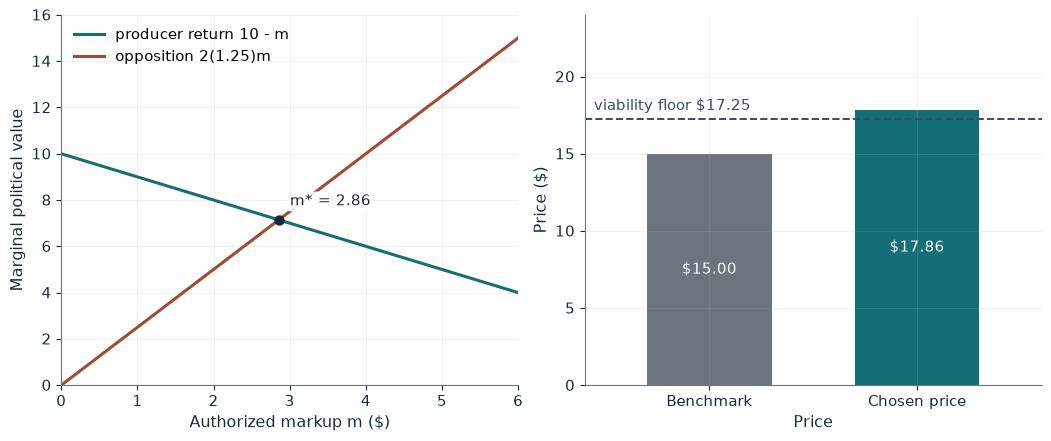

Markup m*            2.86
Price                $17.86
Gap to floor         0.61
Viable at the floor  yes

Worked steps:
  1. 10 - m = 2 x 1.25 x m, so 10 = 3.50 m
  2. m* = 10 / 3.50 = 2.86
  3. Price = 15 + 2.86 = 17.86
  4. Price minus floor = 17.86 - 17.25 = 0.61

Hypothetical teaching numbers, not market data. Setting marginal producer return equal to marginal consumer opposition gives 10 - m = 2.50m, so m* = 10 / 3.50 = 2.86 and the price is 15 + 2.86 = 17.86. $17.86 covers the $17.25 floor.


In [2]:
show(peltzman_picture(k=1.25))

Change one input, `k`, and hold the others at the book's values:

In [3]:
sweep(peltzman_picture, 'k', [0.75, 1.25, 1.75, 2.5], {}, ['Markup m*', 'Price', 'Viable at the floor'])

k | Markup m* | Price | Viable at the floor
0.75 | 4.00 | $19.00 | yes
1.25 | 2.86 | $17.86 | yes
1.75 | 2.22 | $17.22 | no
2.5 | 1.67 | $16.67 | no


At k = 1.25 the price is 17.86, above the 17.25 floor. Doubling consumer opposition to 2.5 cuts the markup to 1.67 and the price to 16.67, a fall of 1.19, and the service is no longer viable.

## 2. Protection for sale and counter-lobbying

Welfare is 900 under free trade and 870 with the tariff; producers gain 120 and offer 90.

$$2.5(900-870)=75, \qquad 120-90=30, \qquad 4(30)=120$$

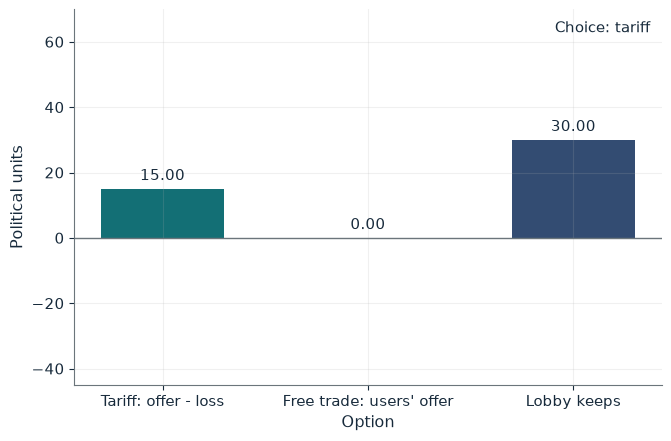

Weighted welfare loss  75.00
Tariff advantage       15.00
Downstream offer       0.00
Choice                 Tariff
Producer offer needed  more than 75.00

Worked steps:
  1. Weighted loss = 2.50 x (900 - 870) = 75.00
  2. Tariff advantage = 90 - 75.00 = 15.00
  3. Compare with the downstream offer 0.00: the tariff wins, 15.00 against 0.00, and producers keep 120 - 90 = 30.00
  4. Needed offer: more than 75.00 + 0.00 = 75.00

Hypothetical teaching numbers, not market data. The tariff costs 2.50 x (900 - 870) = 75.00 weighted units, so the 90 offer leaves an advantage of 90 - 75.00 = 15.00. Against a downstream offer of 0.00, the tariff wins, 15.00 against 0.00, and producers keep 120 - 90 = 30.00. A winning producer offer must exceed 75.00 + 0.00 = 75.00, leaving producers less than 120 - 75.00 = 45.00.


In [4]:
show(lobby_picture(a=2.5, d=0))

Change one input, `d`, and hold the others at the book's values:

In [5]:
sweep(lobby_picture, 'd', [0, 20, 40], {'a': 2.5}, ['Tariff advantage', 'Choice', 'Producer offer needed'])

d | Tariff advantage | Choice | Producer offer needed
0 | 15.00 | Tariff | more than 75.00
20 | 15.00 | Free trade | more than 95.00
40 | 15.00 | Free trade | more than 115.00


With no rival the tariff wins by 15 and producers keep 30. A downstream offer of 20 beats the 15 advantage, so free trade wins; producers would need to offer more than 95.

## 3. Rent-seeking: Tullock contest dissipation

A license worth 1,200 goes to one of five identical firms in a proportional contest.

$$x_i^*=\frac{5-1}{5^2}(1{,}200)=192, \qquad X^*=5(192)=960, \qquad 960+260+60=1{,}280$$

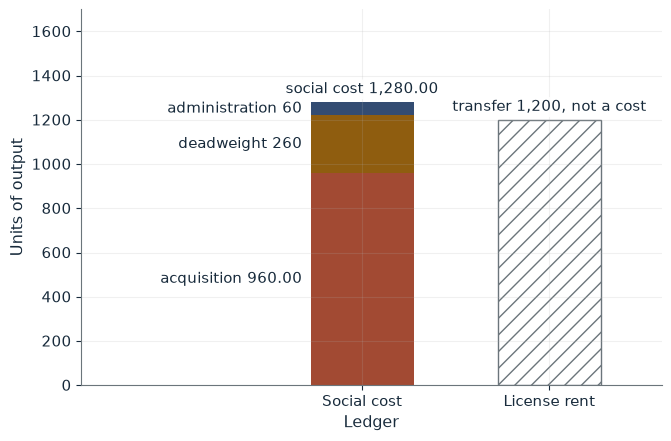

Effort per firm x*            192.00
Total contest effort X*       960.00
Expected net payoff per firm  48.00
Acquisition resources         960.00
Social cost                   1,280.00

Worked steps:
  1. x* = (5 - 1) / 5^2 x 1,200 = 4/25 x 1,200 = 192.00
  2. X* = 5 x 192.00 = 960.00
  3. Expected net = 1,200 / 5 - 192.00 = 240.00 - 192.00 = 48.00
  4. Acquisition resources = 5 x 192.00 = 960.00
  5. Social cost = 960.00 + 260 + 60 = 1,280.00

Hypothetical teaching numbers, not market data. With 5 firms each spends (5 - 1)/5^2 x 1,200 = 192.00, so the contest burns 960.00 of resources. The ledger is 960.00 + 260 + 60 = 1,280.00; the 1,200 license rent is a transfer and is not added again.


In [6]:
show(contest_picture(n=5, mode='contest'))

Change one input, `n`, and hold the others at the book's values:

In [7]:
sweep(contest_picture, 'n', [2, 3, 5, 8], {'mode': 'contest'}, ['Effort per firm x*', 'Total contest effort X*', 'Social cost'])

n | Effort per firm x* | Total contest effort X* | Social cost
2 | 300.00 | 600.00 | 920.00
3 | 266.6667 | 800.00 | 1,120.00
5 | 192.00 | 960.00 | 1,280.00
8 | 131.25 | 1,050.00 | 1,370.00


Each firm spends 192 and nets 48 in expectation; the contest burns 960 and the social-cost ledger is 1,280. An auction (`mode='auction'`) cuts acquisition resources to 35; verified information worth 150 (`mode='info'`) leaves net waste of 810.

## 4. Usury caps: hidden fees and collateral

A one-year loan of \$500 costs \$25 to administer, \$55 in expected default and a \$20 normal return.

$$I^*=\$25+\$55+\$20=\$100, \qquad 0.12(\$500)=\$60, \qquad \$25+\$15+\$20+\$10=\$70$$

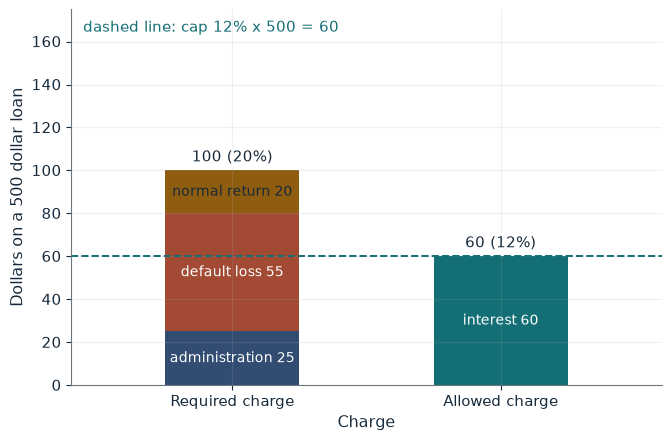

Required charge     $100.00
Required rate       20%
Permitted interest  $60.00
Charge collected    $60.00
Shortfall           $40.00
Decision            Reject

Worked steps:
  1. Required = 25 + 55 + 20 = 100, or 100 / 500 = 20%
  2. Permitted = 0.12 x 500 = 60
  3. Required minus collected = 100 - 60 = 40

Hypothetical teaching numbers, not market data. The break-even charge is 25 + 55 + 20 = 100, a rate of 20%. A 12% cap permits 0.12 x 500 = 60; the lender is short by 40.00 and rejects the loan.


In [8]:
show(usury_picture(cap=0.12, case='plain'))

Change one input, `case`, and hold the others at the book's values:

In [9]:
sweep(usury_picture, 'case', ['plain', 'fee', 'collateral', 'data'], {'cap': 0.12}, ['Required charge', 'Charge collected', 'Decision'])

case | Required charge | Charge collected | Decision
plain | $100.00 | $60.00 | Reject
fee | $100.00 | $110.00 | Lend
collateral | $70.00 | $60.00 | Reject
data | $60.00 | $60.00 | Breaks even


At 12 percent the plain loan is 40 short and is rejected. The excluded 50 fee collects 110 and covers cost; collateral brings the requirement to 70, still 10 short; adding the data saving brings it to 60, so the loan breaks even.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

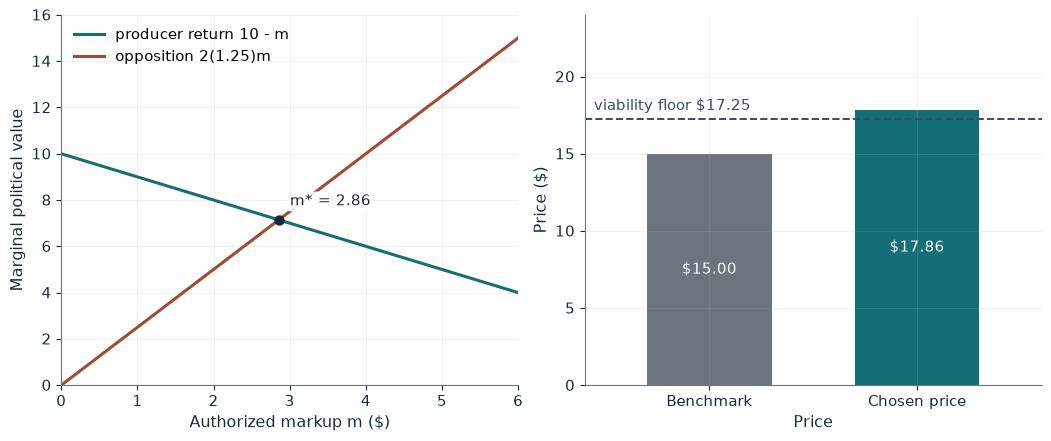

Markup m*            2.86
Price                $17.86
Gap to floor         0.61
Viable at the floor  yes

Worked steps:
  1. 10 - m = 2 x 1.25 x m, so 10 = 3.50 m
  2. m* = 10 / 3.50 = 2.86
  3. Price = 15 + 2.86 = 17.86
  4. Price minus floor = 17.86 - 17.25 = 0.61

Hypothetical teaching numbers, not market data. Setting marginal producer return equal to marginal consumer opposition gives 10 - m = 2.50m, so m* = 10 / 3.50 = 2.86 and the price is 15 + 2.86 = 17.86. $17.86 covers the $17.25 floor.


In [10]:
show(peltzman_picture(k=1.25))

## Practice

**1.** At k = 2.5, what are m* and the price, and is the service viable at the 17.25 floor?

<details><summary>Answer</summary>

10 - m = 5m gives m* = 10/6 = 1.67 and a price of 16.67, below 17.25, so it is not viable.

</details>

**2.** With eight firms in the contest, what is total effort and the social-cost ledger?

<details><summary>Answer</summary>

x* = 7/64 x 1,200 = 131.25, X* = 1,050, and the ledger is 1,050 + 260 + 60 = 1,370.

</details>

**3.** With collateral, what is the required charge and the gap at a 12 percent cap?

<details><summary>Answer</summary>

25 + 15 + 20 + 10 = 70, or 14 percent; 0.12 x 500 = 60, so the gap is 10.

</details>